Import Libraries

In [37]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

import warnings
warnings.filterwarnings('ignore')

Load Dataset

Credit Approval: https://archive.ics.uci.edu/ml/datasets/Credit+Approval    dataset source 

In [38]:
df = "https://archive.ics.uci.edu/ml/machine-learning-databases/credit-screening/crx.data"
df = pd.read_csv(df, header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,00202,0,+
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,00043,560,+
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,00280,824,+
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,00100,3,+
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,00120,0,+


View Dataset

In [41]:
df.tail()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
685,b,21.08,10.085,y,p,e,h,1.25,f,f,0,f,g,00260,0,-
686,a,22.67,0.750,u,g,c,v,2.00,f,t,2,t,g,00200,394,-
687,a,25.25,13.500,y,p,ff,ff,2.00,f,t,1,t,g,00200,1,-
688,b,17.92,0.205,u,g,aa,v,0.04,f,f,0,f,g,00280,750,-
689,b,35.00,3.375,u,g,c,h,8.29,f,f,0,t,g,00000,0,-


Check Dataset Structure

In [42]:
df.shape

(690, 16)

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       690 non-null    object 
 1   1       690 non-null    object 
 2   2       690 non-null    float64
 3   3       690 non-null    object 
 4   4       690 non-null    object 
 5   5       690 non-null    object 
 6   6       690 non-null    object 
 7   7       690 non-null    float64
 8   8       690 non-null    object 
 9   9       690 non-null    object 
 10  10      690 non-null    int64  
 11  11      690 non-null    object 
 12  12      690 non-null    object 
 13  13      690 non-null    object 
 14  14      690 non-null    int64  
 15  15      690 non-null    object 
dtypes: float64(2), int64(2), object(12)
memory usage: 86.4+ KB


In [44]:
df.columns

Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], dtype='int64')

Check Missing Values

In [45]:
df.isnull().sum()

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
dtype: int64

In the Credit Approval dataset, missing values are often stored as ?, not as actual nulls

In [46]:
(df == '?').sum()

0     12
1     12
2      0
3      6
4      6
5      9
6      9
7      0
8      0
9      0
10     0
11     0
12     0
13    13
14     0
15     0
dtype: int64

Replacing the (?) with NaN

In [47]:
import numpy as np
df.replace('?', np.nan, inplace=True)

In [48]:
(df == '?').sum()

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
dtype: int64

In [49]:
df.isnull().sum()

0     12
1     12
2      0
3      6
4      6
5      9
6      9
7      0
8      0
9      0
10     0
11     0
12     0
13    13
14     0
15     0
dtype: int64

In [50]:
import numpy as np
df.replace('?', np.nan, inplace=True)

In [51]:
df.isnull().sum()

0     12
1     12
2      0
3      6
4      6
5      9
6      9
7      0
8      0
9      0
10     0
11     0
12     0
13    13
14     0
15     0
dtype: int64

In [52]:
df.dtypes

0      object
1      object
2     float64
3      object
4      object
5      object
6      object
7     float64
8      object
9      object
10      int64
11     object
12     object
13     object
14      int64
15     object
dtype: object

Filling the object culumns with Mode

In [53]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

Fill Numeric Columns with Median

In [54]:
for col in df.select_dtypes(include=['int64','float64']).columns:
    df[col] = df[col].fillna(df[col].median())

In [55]:
df.isnull().sum()

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
dtype: int64

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       690 non-null    object 
 1   1       690 non-null    object 
 2   2       690 non-null    float64
 3   3       690 non-null    object 
 4   4       690 non-null    object 
 5   5       690 non-null    object 
 6   6       690 non-null    object 
 7   7       690 non-null    float64
 8   8       690 non-null    object 
 9   9       690 non-null    object 
 10  10      690 non-null    int64  
 11  11      690 non-null    object 
 12  12      690 non-null    object 
 13  13      690 non-null    object 
 14  14      690 non-null    int64  
 15  15      690 non-null    object 
dtypes: float64(2), int64(2), object(12)
memory usage: 86.4+ KB


Visualize

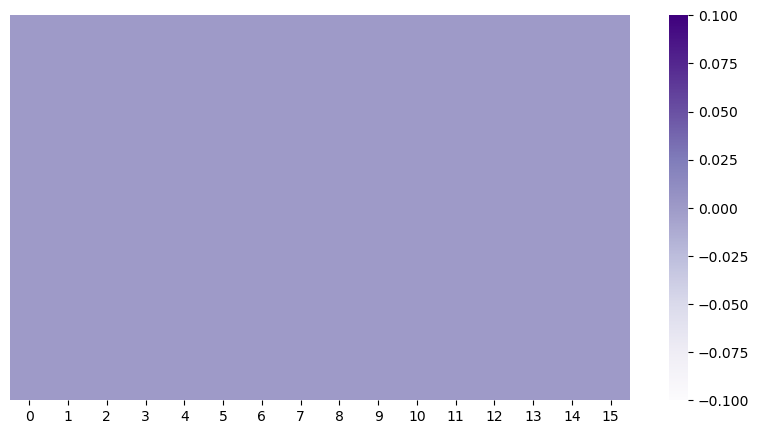

In [57]:
plt.figure(figsize=(10,5))
sns.heatmap(
    df.isnull(),
    yticklabels=False,
    cmap='Purples'
)
plt.show()

Check Duplicates

In [58]:
df.duplicated().sum()

0

Statistical Summary

In [59]:
df.describe()

,2,7,10,14
count,690.000000,690.000000,690.00000,690.000000
mean,4.758725,2.223406,2.40000,1017.385507
std,4.978163,3.346513,4.86294,5210.102598
min,0.000000,0.000000,0.00000,0.000000
25%,1.000000,0.165000,0.00000,0.000000
50%,2.750000,1.000000,0.00000,5.000000
75%,7.207500,2.625000,3.00000,395.500000
max,28.000000,28.500000,67.00000,100000.000000


In [60]:
df.dtypes

0      object
1      object
2     float64
3      object
4      object
5      object
6      object
7     float64
8      object
9      object
10      int64
11     object
12     object
13     object
14      int64
15     object
dtype: object

Explore Target Variable
Shows the number of approved versus rejected applications

The target variable is relatively balanced, with approximately 44% approved applications and 56% rejected applications. Therefore, no special class balancing techniques such as SMOTE, undersampling, or oversampling were required before model training

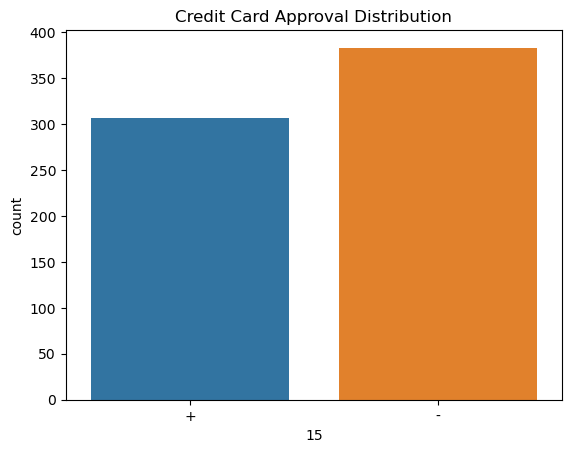

In [61]:
sns.countplot(x=15, data=df)

plt.title('Credit Card Approval Distribution')
plt.show()

In [62]:
df[15].value_counts()

15
-    383
+    307
Name: count, dtype: int64

In [63]:
df[15].value_counts(normalize=True) * 100

15
-    55.507246
+    44.492754
Name: proportion, dtype: float64

The descriptive statistics indicate that Feature 14 has a substantially larger range and standard deviation than the other numerical features. Therefore, feature scaling will be applied to standardize all features before model training and prevent variables with larger magnitudes from dominating the learning process.

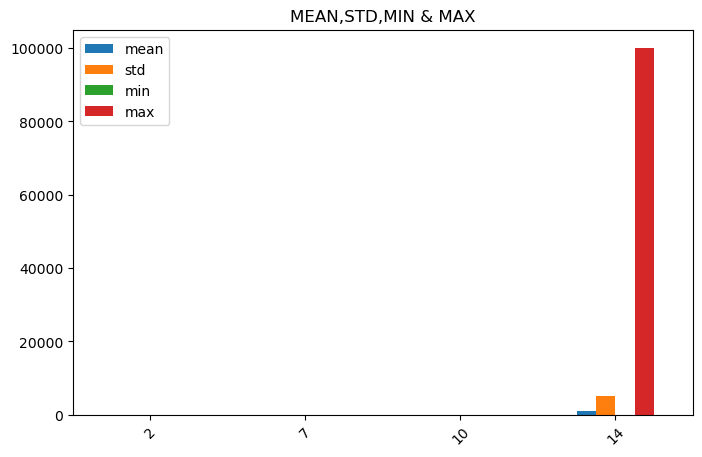

In [64]:

summary = df.describe().T

summary[['mean','std','min','max']].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('MEAN,STD,MIN & MAX')

plt.xticks(rotation=45)

plt.show()

The numerical features exhibit positively skewed distributions, with most observations concentrated at lower values and a small number of larger observations. Feature 14 shows the greatest variability and contains several high-value observations. These distributions are common in financial datasets and were retained. Feature scaling was applied before model training to ensure comparable feature magnitudes.

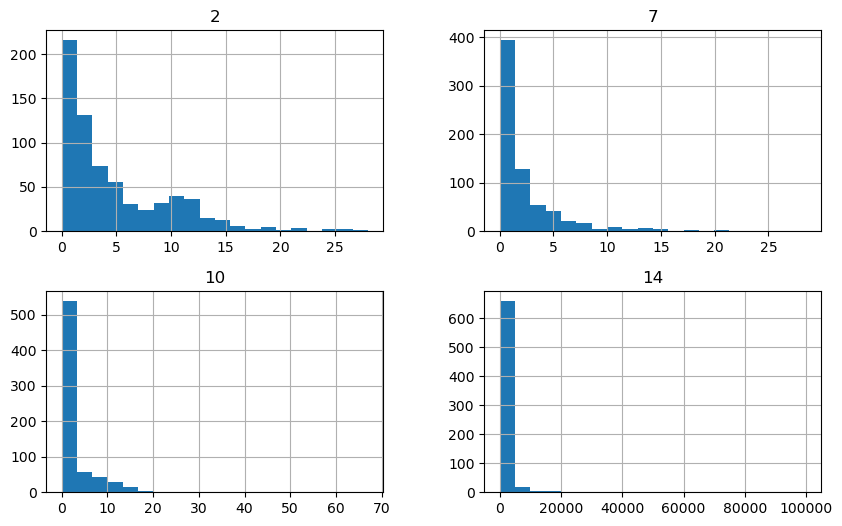

In [65]:
df.hist(
    figsize=(10,6),
    bins=20
)
plt.show()

Correlation Analysis
First encode categorical columns.

In [66]:
df_encoded = pd.get_dummies(
    df,
    drop_first=True
)

In [67]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

In [68]:
df.dtypes

0       int32
1       int32
2     float64
3       int32
4       int32
5       int32
6       int32
7     float64
8       int32
9       int32
10      int64
11      int32
12      int32
13      int32
14      int64
15      int32
dtype: object

In [69]:
df.head(2)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,1,156,0.00,1,0,12,7,1.25,1,1,1,0,0,68,0,0
1,0,328,4.46,1,0,10,3,3.04,1,1,6,0,0,11,560,0


The correlation heatmap shows generally weak linear relationships among the features. No severe multicollinearity is observed, suggesting that the predictors provide distinct information. Correlation values involving encoded categorical variables should be interpreted cautiously because the numerical labels do not represent actual magnitudes.

Correlation

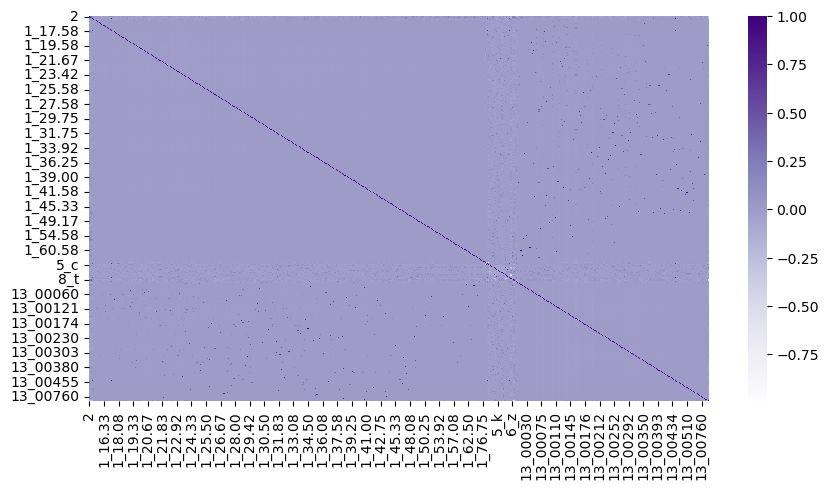

In [70]:
plt.figure(figsize=(10,5))

sns.heatmap(
    df_encoded.corr(),
    cmap='Purples'
)

plt.show()

Separate Features and Target

In [71]:
# Display all column names
print(df.columns.tolist())

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [72]:
X = df.drop(columns=[15])
y = df[15]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (690, 15)
Target shape: (690,)


In [73]:
X

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,1,156,0.000,1,0,12,7,1.25,1,1,1,0,0,68,0
1,0,328,4.460,1,0,10,3,3.04,1,1,6,0,0,11,560
2,0,89,0.500,1,0,10,3,1.50,1,0,0,0,0,96,824
3,1,125,1.540,1,0,12,7,3.75,1,1,5,1,0,31,3
4,1,43,5.625,1,0,12,7,1.71,1,0,0,0,2,37,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
685,1,52,10.085,2,2,4,3,1.25,0,0,0,0,0,90,0
686,0,71,0.750,1,0,1,7,2.00,0,1,2,1,0,67,394
687,0,97,13.500,2,2,5,2,2.00,0,1,1,1,0,67,1
688,1,20,0.205,1,0,0,7,0.04,0,0,0,0,0,96,750


In [74]:
y

0      0
1      0
2      0
3      0
4      0
      ..
685    1
686    1
687    1
688    1
689    1
Name: 15, Length: 690, dtype: int32

Train Test Split

In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

Feature Scaling

In [76]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

Logistic Regression

In [77]:
lr = LogisticRegression(
    max_iter=1000
)

lr.fit(
    X_train_scaled,
    y_train
)

lr_pred = lr.predict(
    X_test_scaled
)

lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.8405797101449275


Decision Tree

In [78]:
dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(
    X_train,
    y_train
)

dt_pred = dt.predict(
    X_test
)

dt_accuracy = accuracy_score(
    y_test,
    dt_pred
)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.8115942028985508


Random Forest

In [79]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(
    X_train,
    y_train
)

rf_pred = rf.predict(
    X_test
)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.8743961352657005


KNN

In [82]:
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(
    X_train_scaled,
    y_train
)

knn_pred = knn.predict(
    X_test_scaled
)

knn_accuracy = accuracy_score(
    y_test,
    knn_pred
)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.855072463768116


Compare Models

In [83]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'KNN'
    ],
    'Accuracy': [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        knn_accuracy
    ]
})

results.sort_values(
    by='Accuracy',
    ascending=False,
    inplace=True
)

print(results)

                 Model  Accuracy
2        Random Forest  0.874396
3                  KNN  0.855072
0  Logistic Regression  0.840580
1        Decision Tree  0.811594


Visual Comparison

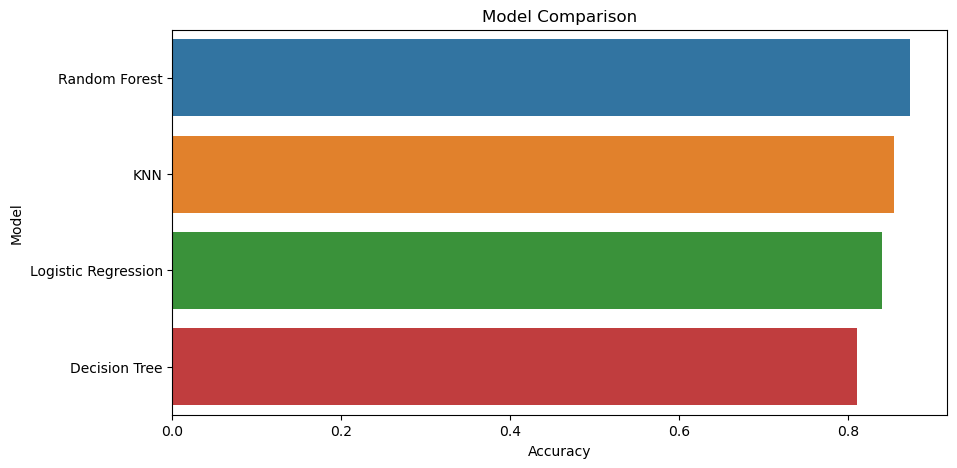

In [84]:
plt.figure(figsize=(10,5))

sns.barplot(
    x='Accuracy',
    y='Model',
    data=results
)

plt.title("Model Comparison")

plt.show()

Classification Report

Use the best model (Random Forest).
Shows:
Precision
Recall
F1-score
Support

In [91]:
print(
    classification_report(
        y_test,
        rf_pred
    )
)

              precision    recall  f1-score   support

           0       0.87      0.87      0.87        97
           1       0.88      0.88      0.88       110

    accuracy                           0.87       207
   macro avg       0.87      0.87      0.87       207
weighted avg       0.87      0.87      0.87       207



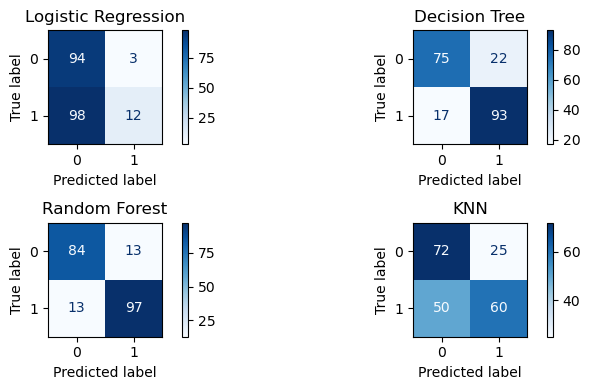

In [97]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create predictions
lr_pred = lr.predict(X_test)
dt_pred = dt.predict(X_test)
rf_pred = rf.predict(X_test)
knn_pred = knn.predict(X_test)

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(8, 4))

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred, ax=axes[0, 0], cmap='Blues'
)
axes[0, 0].set_title('Logistic Regression')

# Decision Tree
ConfusionMatrixDisplay.from_predictions(
    y_test, dt_pred, ax=axes[0, 1], cmap='Blues'
)
axes[0, 1].set_title('Decision Tree')

# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, ax=axes[1, 0], cmap='Blues'
)
axes[1, 0].set_title('Random Forest')

# KNN
ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred, ax=axes[1, 1], cmap='Blues'
)
axes[1, 1].set_title('KNN')

plt.tight_layout()
plt.show()

In [98]:
from sklearn.metrics import confusion_matrix
import pandas as pd

# Random Forest
y_pred = rf.predict(X_test)   

cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=['Actual 0', 'Actual 1'],
    columns=['Predicted 0', 'Predicted 1']
)

print(cm_df)

          Predicted 0  Predicted 1
Actual 0           84           13
Actual 1           13           97


Confusion Matrix

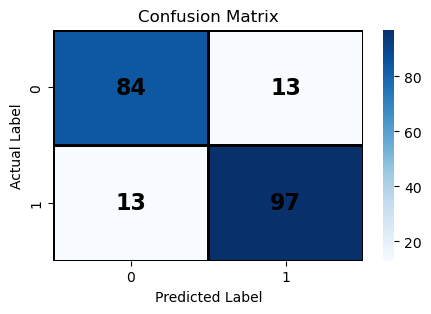

In [101]:
plt.figure(figsize=(5,3))

ax = sns.heatmap(
    cm,
    cmap='Blues',
    cbar=True,
    linewidths=1,
    linecolor='black'
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j + 0.5,
            i + 0.5,
            str(cm[i, j]),
            ha='center',
            va='center',
            color='black',
            fontsize=16,
            fontweight='bold'
        )

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.show()

Feature Importance

In [100]:
importance = pd.DataFrame({

    'Feature':X.columns,

    'Importance':rf.feature_importances_

})

In [102]:
importance.sort_values(
    by='Importance',
    ascending=False,
    inplace=True
)

print(importance.head(15))

    Feature  Importance
8         8    0.282858
10       10    0.101422
7         7    0.101161
14       14    0.085126
2         2    0.083330
1         1    0.078274
13       13    0.069844
9         9    0.055768
5         5    0.054411
6         6    0.027588
0         0    0.013561
3         3    0.012752
11       11    0.012012
4         4    0.011069
12       12    0.010823


Visualization:

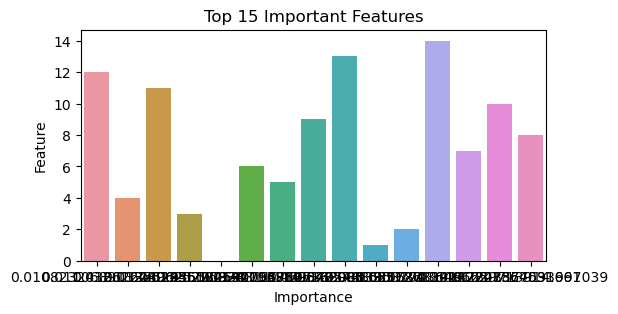

In [103]:
plt.figure(figsize=(6,3))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance.head(15)
)

plt.title(
    "Top 15 Important Features"
)

plt.show()

Hyperparameter Tuning

In [104]:
param_grid = {

    'n_estimators':[100,200,300],

    'max_depth':[5,10,15,None],

    'min_samples_split':[2,5,10]
}

In [105]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    RandomForestClassifier(),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best Accuracy:", grid.best_score_)

Best Parameters: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 100}
Best Accuracy: 0.8736039518900343


In [106]:
grid.fit(
    X_train,
    y_train
)

GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid={'max_depth': [5, 10, 15, None],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy')

In [107]:
print(grid.best_score_)

0.875708762886598


Save Best Model

In [108]:
import joblib

joblib.dump(
    rf,
    "credit_card_approval_model.pkl"
)

['credit_card_approval_model.pkl']

Save Scaler

In [109]:
joblib.dump(
    scaler,
    "scaler.pkl"
)

['scaler.pkl']

In [110]:
import os

print("Model saved in:", os.path.abspath("credit_card_approval_model.pkl"))

Model saved in: c:\PROJECT\ML\mlproject\credit_card_approval_model.pkl
